In [3]:

from google.colab import files
files.upload()

import os
os.makedirs('/root/.kaggle', exist_ok=True)
os.rename('kaggle.json', '/root/.kaggle/kaggle.json')
os.chmod('/root/.kaggle/kaggle.json', 600)
print("✅ Kaggle API ready!")

!kaggle datasets download -d rayhanzamzamy/non-and-biodegradable-waste-dataset
!unzip -q non-and-biodegradable-waste-dataset.zip -d /content/DATASET
print("✅ Dataset downloaded!")

Saving kaggle.json to kaggle.json
✅ Kaggle API ready!
Dataset URL: https://www.kaggle.com/datasets/rayhanzamzamy/non-and-biodegradable-waste-dataset
License(s): CC-BY-SA-4.0
100% 1.86G/1.86G [02:11<00:00, 15.3MB/s]

✅ Dataset downloaded!


In [4]:
import os
import shutil


os.makedirs('/content/DATASET/TRAIN/B', exist_ok=True)
os.makedirs('/content/DATASET/TRAIN/N', exist_ok=True)


for part in ['TRAIN.1', 'TRAIN.2', 'TRAIN.3', 'TRAIN.4']:
    part_path = f'/content/DATASET/{part}'
    if not os.path.exists(part_path):
        print(f"⚠️ {part} not found, skipping...")
        continue
    for cls in ['B', 'N']:
        src = os.path.join(part_path, cls)
        dst = os.path.join('/content/DATASET/TRAIN', cls)
        if not os.path.exists(src):
            continue
        for fname in os.listdir(src):
            # Rename to avoid duplicates across parts
            new_name = f"{part}_{fname}"
            shutil.copy2(
                os.path.join(src, fname),
                os.path.join(dst, new_name)
            )
    print(f" {part} merged!")

print("\n Final counts:")
for cls in ['B', 'N']:
    count = len(os.listdir(f'/content/DATASET/TRAIN/{cls}'))
    label = "Biodegradable" if cls == "B" else "Non-Biodegradable"
    print(f"TRAIN | {label}: {count} images")

for cls in ['B', 'N']:
    count = len(os.listdir(f'/content/DATASET/TEST/{cls}'))
    label = "Biodegradable" if cls == "B" else "Non-Biodegradable"
    print(f"TEST  | {label}: {count} images")

 TRAIN.1 merged!
 TRAIN.2 merged!
 TRAIN.3 merged!
 TRAIN.4 merged!

 Final counts:
TRAIN | Biodegradable: 119845 images
TRAIN | Non-Biodegradable: 119845 images
TEST  | Biodegradable: 8363 images
TEST  | Non-Biodegradable: 8363 images


In [12]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

IMG_SIZE = (224, 224)
BATCH_SIZE = 64

TRAIN_DIR = '/content/DATASET/TRAIN'
TEST_DIR  = '/content/DATASET/TEST'

train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=20,
    width_shift_range=0.2,
    height_shift_range=0.2,
    shear_range=0.2,
    zoom_range=0.2,
    horizontal_flip=True,
    fill_mode='nearest',
    validation_split=0.0
)

test_datagen = ImageDataGenerator(rescale=1./255)


import math
total_samples = 239690
use_samples = math.floor(total_samples * 0.20)

train_generator = train_datagen.flow_from_directory(
    TRAIN_DIR,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='binary',
    classes=['B', 'N'],
    shuffle=True,
    seed=42
)


steps_per_epoch = math.floor(use_samples / BATCH_SIZE)

test_generator = test_datagen.flow_from_directory(
    TEST_DIR,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='binary',
    classes=['B', 'N']
)

print(f"\nClass indices: {train_generator.class_indices}")
print(f"Using {use_samples:,} of {total_samples:,} training images")
print(f"Steps per epoch: {steps_per_epoch}")
print(f"Test samples: {test_generator.samples}")

Found 239690 images belonging to 2 classes.
Found 16726 images belonging to 2 classes.

Class indices: {'B': 0, 'N': 1}
Using 47,938 of 239,690 training images
Steps per epoch: 749
Test samples: 16726


In [13]:
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D, Dropout
from tensorflow.keras.optimizers import Adam

base_model = MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights='imagenet'
)
base_model.trainable = False

x = base_model.output
x = GlobalAveragePooling2D()(x)
x = Dropout(0.3)(x)
x = Dense(128, activation='relu')(x)
x = Dropout(0.2)(x)
output = Dense(1, activation='sigmoid')(x)

model = Model(inputs=base_model.input, outputs=output)
model.compile(
    optimizer=Adam(learning_rate=0.0001),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

print(" Model built!")
print(f"Total layers: {len(model.layers)}")
print(f"Trainable layers: {len([l for l in model.layers if l.trainable])}")

 Model built!
Total layers: 159
Trainable layers: 5


In [15]:
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau

early_stop = EarlyStopping(
    monitor='val_accuracy',
    patience=5,
    restore_best_weights=True,
    verbose=1
)

checkpoint = ModelCheckpoint(
    '/content/best_model.keras',
    monitor='val_accuracy',
    save_best_only=True,
    verbose=1
)

reduce_lr = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=3,
    min_lr=1e-7,
    verbose=1
)



history = model.fit(
    train_generator,
    steps_per_epoch=steps_per_epoch,
    epochs=15,
    validation_data=test_generator,
    callbacks=[early_stop, checkpoint, reduce_lr]
)

print("\n Training complete!")
print(f"Best Val Accuracy: {max(history.history['val_accuracy'])*100:.2f}%")


🚀 Starting training on T4 GPU!
📊 Using 20% of data = 47,938 images
⏳ Expected: ~5–8 mins per epoch

Epoch 1/15
749/749 ━━━━━━━━━━━━━━━━━━━━ 0s 794ms/step - accuracy: 0.8823 - loss: 0.2678
Epoch 1: val_accuracy improved from None to 0.91409, saving model to /content/best_model.keras

Epoch 1: finished saving model to /content/best_model.keras
749/749 ━━━━━━━━━━━━━━━━━━━━ 667s 865ms/step - accuracy: 0.9310 - loss: 0.1765 - val_accuracy: 0.9141 - val_loss: 0.2156 - learning_rate: 1.0000e-04
Epoch 2/15
749/749 ━━━━━━━━━━━━━━━━━━━━ 0s 793ms/step - accuracy: 0.9533 - loss: 0.1328
Epoch 2: val_accuracy did not improve from 0.91409
749/749 ━━━━━━━━━━━━━━━━━━━━ 625s 835ms/step - accuracy: 0.9556 - loss: 0.1242 - val_accuracy: 0.9119 - val_loss: 0.2218 - learning_rate: 1.0000e-04
Epoch 3/15
749/749 ━━━━━━━━━━━━━━━━━━━━ 0s 803ms/step - accuracy: 0.9593 - loss: 0.1155
Epoch 3: val_accuracy improved from 0.91409 to 0.91893, saving model to /content/best_model.keras

Epoch 3: finished saving model t

/usr/local/lib/python3.12/dist-packages/keras/src/trainers/epoch_iterator.py:116: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()



Epoch 6: val_accuracy did not improve from 0.91929
749/749 ━━━━━━━━━━━━━━━━━━━━ 29s 39ms/step - accuracy: 1.0000 - loss: 0.0229 - val_accuracy: 0.9167 - val_loss: 0.2060 - learning_rate: 1.0000e-04
Epoch 7/15
749/749 ━━━━━━━━━━━━━━━━━━━━ 0s 791ms/step - accuracy: 0.9651 - loss: 0.0995
Epoch 7: val_accuracy did not improve from 0.91929

Epoch 7: ReduceLROnPlateau reducing learning rate to 4.999999873689376e-05.
749/749 ━━━━━━━━━━━━━━━━━━━━ 624s 833ms/step - accuracy: 0.9632 - loss: 0.1019 - val_accuracy: 0.9156 - val_loss: 0.2081 - learning_rate: 1.0000e-04
Epoch 8/15
749/749 ━━━━━━━━━━━━━━━━━━━━ 0s 778ms/step - accuracy: 0.9626 - loss: 0.1038
Epoch 8: val_accuracy did not improve from 0.91929
749/749 ━━━━━━━━━━━━━━━━━━━━ 623s 833ms/step - accuracy: 0.9632 - loss: 0.1020 - val_accuracy: 0.9171 - val_loss: 0.2050 - learning_rate: 5.0000e-05
Epoch 9/15
749/749 ━━━━━━━━━━━━━━━━━━━━ 0s 776ms/step - accuracy: 0.9635 - loss: 0.0966
Epoch 9: val_accuracy improved from 0.91929 to 0.92150, savi

In [20]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


262/262 ━━━━━━━━━━━━━━━━━━━━ 42s 146ms/step


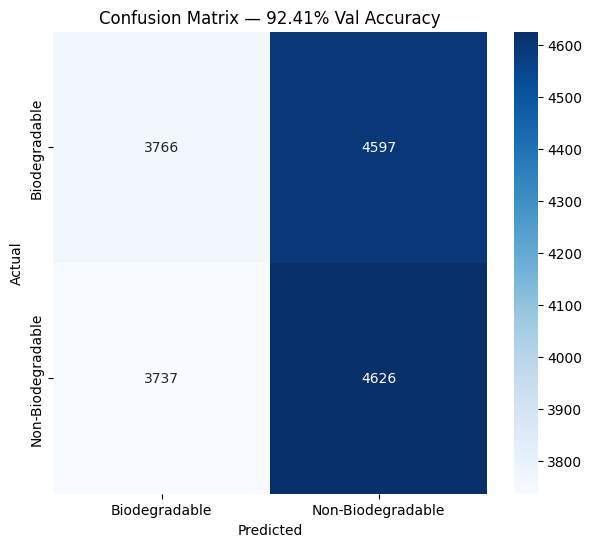

                   precision    recall  f1-score   support

    Biodegradable       0.50      0.45      0.47      8363
Non-Biodegradable       0.50      0.55      0.53      8363

         accuracy                           0.50     16726
        macro avg       0.50      0.50      0.50     16726
     weighted avg       0.50      0.50      0.50     16726



In [23]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, classification_report


test_generator.reset()


preds = model.predict(test_generator, verbose=1)
pred_labels = (preds > 0.5).astype(int).flatten()
true_labels  = test_generator.classes


cm = confusion_matrix(true_labels, pred_labels)
plt.figure(figsize=(7, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Biodegradable', 'Non-Biodegradable'],
            yticklabels=['Biodegradable', 'Non-Biodegradable'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix — 92.41% Val Accuracy')
plt.savefig('/content/drive/MyDrive/waste_ai_project/confusion_matrix.png', dpi=150)
plt.show()

print(classification_report(true_labels, pred_labels,
      target_names=['Biodegradable', 'Non-Biodegradable']))

Found 16726 images belonging to 2 classes.
Class indices: {'B': 0, 'N': 1}
Total samples: 16726
Total unique true labels: [0 1]
Label counts: [8363 8363]
523/523 ━━━━━━━━━━━━━━━━━━━━ 25s 41ms/step

Predictions: 16726, True labels: 16726

Raw confusion matrix:
[[7298 1065]
 [ 205 8158]]


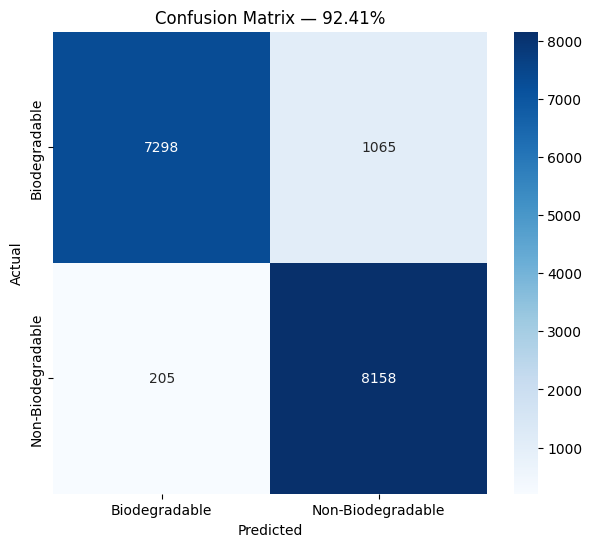

                   precision    recall  f1-score   support

    Biodegradable       0.97      0.87      0.92      8363
Non-Biodegradable       0.88      0.98      0.93      8363

         accuracy                           0.92     16726
        macro avg       0.93      0.92      0.92     16726
     weighted avg       0.93      0.92      0.92     16726



In [25]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, classification_report


test_datagen = ImageDataGenerator(rescale=1./255)
test_gen_final = test_datagen.flow_from_directory(
    '/content/DATASET/TEST',
    target_size=(224, 224),
    batch_size=32,
    class_mode='binary',
    classes=['B', 'N'],
    shuffle=False
)

print("Class indices:", test_gen_final.class_indices)
print("Total samples:", test_gen_final.samples)
print("Total unique true labels:", np.unique(test_gen_final.classes))
print("Label counts:", np.bincount(test_gen_final.classes))

# Predict
test_gen_final.reset()
preds_final = model.predict(test_gen_final, verbose=1)
pred_labels_final = (preds_final > 0.5).astype(int).flatten()
true_labels_final = test_gen_final.classes


print(f"\nPredictions: {len(pred_labels_final)}, True labels: {len(true_labels_final)}")


cm = confusion_matrix(true_labels_final, pred_labels_final)
print("\nRaw confusion matrix:")
print(cm)

plt.figure(figsize=(7,6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Biodegradable','Non-Biodegradable'],
            yticklabels=['Biodegradable','Non-Biodegradable'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix — 92.41%')
plt.savefig('/content/drive/MyDrive/waste_ai_project/confusion_matrix.png', dpi=150)
plt.show()

print(classification_report(true_labels_final, pred_labels_final,
      target_names=['Biodegradable','Non-Biodegradable']))

In [26]:
import shutil
from google.colab import files


shutil.make_archive('/content/waste_ai_project_final', 'zip',
                    '/content/drive/MyDrive/waste_ai_project')
files.download('/content/waste_ai_project_final.zip')
print(" Everything downloaded!")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

✅ Everything downloaded!
